# 3.9 Estrategia de reajuste del modelo

> Borrador de la sección 3.9 (Gerónimo). Se integra en `model_development.ipynb`. Cada decisión sigue el formato **Decisión / Alternativas / Por qué / Evidencia**.

**Qué pide el enunciado:** diseñar cómo se detectaría que el modelo se degradó o que los datos cambiaron, con qué criterio y frecuencia se reentrenaría, y cómo se validaría y pondría en producción la versión nueva.

**Qué hicimos:** definimos qué se mide y cuándo salta cada alarma, y lo probamos con una simulación de 2024-2025: un modelo congelado, entrenado con 2019-2023, se recorre mes a mes y trimestre a trimestre con la base v1.

> Las cifras salen de `python -m src.monitoreo` con el **modelo v1**. Para recalcularlas se pone `RECALCULAR = True` en la primera celda de código.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", message="IProgress not found")

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":      # el borrador vive en notebooks/; el notebook final, en la raiz de final-project/
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from src import config, monitoreo as M

RECALCULAR = False     # True vuelve a correr la simulacion completa (unos 70 s) y reescribe resultados/monitoreo_*
RES = RAIZ / "resultados"
if RECALCULAR:
    M.main()

mensual = pd.read_csv(RES / "monitoreo_mensual.csv")
trimestral = pd.read_csv(RES / "monitoreo_trimestral.csv")
historico = pd.read_csv(RES / "monitoreo_psi_historico.csv")
cr = json.loads((RES / "monitoreo_campeon_retador.json").read_text(encoding="utf-8"))
print(f"Meses simulados: {len(mensual)} | trimestres: {len(trimestral)} | contratos de la evaluación campeón/retador: {cr['n_evaluacion']:,}")

Meses simulados: 24 | trimestres: 8 | contratos de la evaluación campeón/retador: 80,652


## Qué puede cambiar

Un modelo de este problema se enfrenta a cinco tipos de cambio, y todos aparecen en estos datos:

| Tipo | Ejemplo en los datos |
|---|---|
| Cambian las **entradas** | `dias_firma_a_inicio`: antes de 2021 muchos contratos tenían el inicio anterior a la firma |
| Cambia el **comportamiento** | el 1 % de mayor puntaje de 2025-T3 era casi todo de una entidad que no amplió sus plazos |
| Cambia el **registro de la etiqueta** | `y_dias` salta en 2025 por cómo se guarda `dias_adicionados` |
| **Estacionalidad** | la tasa de positivos va de 34 % en enero a 16 % en octubre |
| Etiquetas **tardías** | el resultado se conoce meses después de firmar |

Lo comprobamos con los datos:

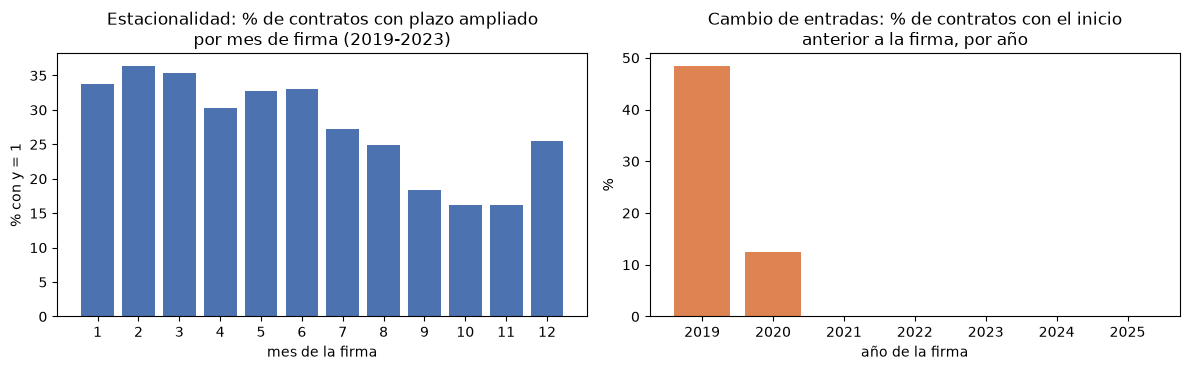

In [2]:
BASE = config.BASE_V1
if BASE.exists():
    b = pd.read_parquet(BASE, columns=["fecha_de_firma", "fecha_de_inicio_del_contrato", "anio_firma", "y", "eval_madura"])
    firma, inicio = b["fecha_de_firma"].dt.normalize(), pd.to_datetime(b["fecha_de_inicio_del_contrato"]).dt.normalize()
    b["inicio_antes_de_firma"] = (inicio - firma).dt.days < 0

    fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
    por_mes = b[(b["anio_firma"] <= 2023) & b["eval_madura"]].groupby(b["fecha_de_firma"].dt.month)["y"].mean()
    ejes[0].bar(por_mes.index, 100 * por_mes.values, color="#4C72B0")
    ejes[0].set_title("Estacionalidad: % de contratos con plazo ampliado\npor mes de firma (2019-2023)")
    ejes[0].set_xlabel("mes de la firma"); ejes[0].set_ylabel("% con y = 1"); ejes[0].set_xticks(range(1, 13))
    cambio = 100 * b.groupby("anio_firma")["inicio_antes_de_firma"].mean()
    ejes[1].bar(cambio.index, cambio.values, color="#DD8452")
    ejes[1].set_title("Cambio de entradas: % de contratos con el inicio\nanterior a la firma, por año")
    ejes[1].set_xlabel("año de la firma"); ejes[1].set_ylabel("%")
    plt.tight_layout(); plt.show()
else:
    print("Esta celda usa data/processed/v1_A/base_contratos.parquet")

**Interpretación:**
- **Estacionalidad.** La tasa de positivos cambia más de 2 veces según el mes. Si el monitor comparara un mes contra un promedio anual, saltaría una alarma cada enero sin que nada hubiera cambiado. Por eso todas las comparaciones son contra **el mismo mes o trimestre del año anterior**.
- **Cambio de régimen.** En 2019 el 48 % de los contratos tenía la fecha de inicio anterior a la firma, en 2020 el 12 %, y desde 2021 casi ninguno. Por eso la referencia del monitor son los años 2022-2023 y no todo el entrenamiento: con 2019-2023 una variable que ya no cambia saldría siempre como "distinta".

## Qué se mide, con qué frecuencia y cuándo salta cada alarma

**Decisión:** tres capas con frecuencias distintas.

| Capa | Frecuencia | Por qué esa frecuencia |
|---|---|---|
| **Entradas y puntaje** (PSI) | Mensual | No necesita etiquetas: las entradas se conocen al firmar |
| **Desempeño** (ROC-AUC, PR-AUC, precisión en el top 1 %) | Trimestral | Necesita etiquetas, que llegan con retraso, y el ROC-AUC mensual oscila de 0,71 a 0,87 solo por la composición de cada mes |
| **Etiqueta** (tasa de positivos) | Trimestral | Detecta cambios de comportamiento y de registro |

**Alternativas consideradas:** un solo indicador mensual de desempeño; comparar contra el promedio histórico.

**Por qué no:** el desempeño mensual es ruido, y el promedio histórico no separa la estacionalidad de un cambio real.

**Evidencia:** las reglas, tal como están en el código (`src/monitoreo.py`):

In [3]:
reglas = pd.DataFrame([
    ("PSI de 10 entradas, cada mes", f"{M.MIN_VARIABLES_REVISAR} o más variables con PSI ≥ {M.PSI_AVISO}, o una ≥ {M.PSI_ALARMA}", "revisar; nunca reentrena por sí solo"),
    ("PSI del puntaje, cada mes", f"≥ {M.PSI_AVISO} (aviso), ≥ {M.PSI_ALARMA} (alarma)", "frente al mismo mes del año anterior"),
    ("Tasa de positivos, cada trimestre", f"cambio ≥ {M.DELTA_TASA_BASE:.0%} frente al mismo trimestre", "investigar: ¿comportamiento o registro?"),
    ("ROC-AUC, cada trimestre", f"cae ≥ {M.DELTA_ROC} y el IC 95 % por entidad excluye 0", f"alarma si se repite {M.PERSISTENCIA} trimestres seguidos"),
    ("Precisión del 1 % de mayor puntaje", "menor que la tasa base del trimestre", f"alarma si se repite {M.PERSISTENCIA} trimestres seguidos"),
    ("Cohorte con etiquetas", f"solo si ≥ {M.MADUREZ_MIN:.0%} de sus contratos ya maduró", "si no, se espera"),
], columns=["Señal", "Aviso", "Acción"])
pd.set_option("display.max_colwidth", None)
display(reglas)

,Señal,Aviso,Acción
0,"PSI de 10 entradas, cada mes","2 o más variables con PSI ≥ 0.1, o una ≥ 0.25",revisar; nunca reentrena por sí solo
1,"PSI del puntaje, cada mes","≥ 0.1 (aviso), ≥ 0.25 (alarma)",frente al mismo mes del año anterior
2,"Tasa de positivos, cada trimestre",cambio ≥ 5% frente al mismo trimestre,investigar: ¿comportamiento o registro?
3,"ROC-AUC, cada trimestre",cae ≥ 0.03 y el IC 95 % por entidad excluye 0,alarma si se repite 2 trimestres seguidos
4,Precisión del 1 % de mayor puntaje,menor que la tasa base del trimestre,alarma si se repite 2 trimestres seguidos
5,Cohorte con etiquetas,solo si ≥ 95% de sus contratos ya maduró,"si no, se espera"


## Simulación 2024-2025

El modelo se entrenó con 2019-2023 y no se vuelve a entrenar. A continuación, lo que el monitor habría mostrado.

### Entradas y puntaje (mensual)

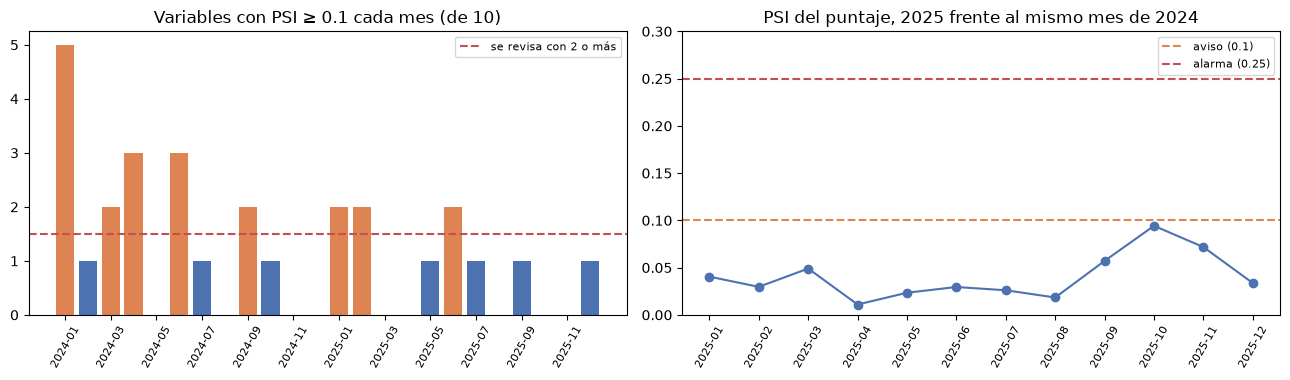

,PSI de las entradas,mediana,% de valores ≥ 0.25
0,entre años consecutivos del entrenamiento (2021-2023),0.090,28.750
1,producción 2024-2025,0.032,0.833


In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 3.9))
x = np.arange(len(mensual))
color = np.where(mensual["estado_entradas"] == "revisar", "#DD8452", "#4C72B0")
ejes[0].bar(x, mensual["n_variables_psi_alto"], color=color)
ejes[0].axhline(M.MIN_VARIABLES_REVISAR - 0.5, color="#C44E52", linestyle="--", label=f"se revisa con {M.MIN_VARIABLES_REVISAR} o más")
ejes[0].set_xticks(x[::2]); ejes[0].set_xticklabels(mensual["mes"][::2], rotation=60, fontsize=8)
ejes[0].set_title(f"Variables con PSI ≥ {M.PSI_AVISO} cada mes (de 10)"); ejes[0].legend(fontsize=8)

p = mensual.dropna(subset=["psi_score_vs_anio_anterior"])
ejes[1].plot(p["mes"], p["psi_score_vs_anio_anterior"], marker="o", color="#4C72B0")
ejes[1].axhline(M.PSI_AVISO, color="#DD8452", linestyle="--", label=f"aviso ({M.PSI_AVISO})")
ejes[1].axhline(M.PSI_ALARMA, color="#C44E52", linestyle="--", label=f"alarma ({M.PSI_ALARMA})")
ejes[1].set_ylim(0, 0.3); ejes[1].tick_params(axis="x", rotation=60, labelsize=8)
ejes[1].set_title("PSI del puntaje, 2025 frente al mismo mes de 2024"); ejes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

cols = M.FEATURES_PSI["num"] + M.FEATURES_PSI["cat"]
hist, prod = historico[cols].stack(), mensual[["psi_" + c for c in cols]].stack()
display(pd.DataFrame({"PSI de las entradas": ["entre años consecutivos del entrenamiento (2021-2023)", "producción 2024-2025"],
                      "mediana": [hist.median(), prod.median()],
                      f"% de valores ≥ {M.PSI_ALARMA}": [100 * (hist >= M.PSI_ALARMA).mean(), 100 * (prod >= M.PSI_ALARMA).mean()]}).round(3))

**Interpretación:**
- **Entradas.** En 8 de 24 meses el monitor pide revisar (2 o más variables con PSI alto). Las que más pesan son la duración planeada y el sector.
- **Puntaje.** Los 12 meses de 2025 quedan normales frente al mismo mes de 2024 (PSI máximo 0,094): el modelo reparte los puntajes como el año anterior.
- **El PSI avisa, pero no decide.** Entre años consecutivos del propio entrenamiento el PSI ya era mucho mayor que el de 2024-2025, porque el SECOP II creció y cambió rápido. Un PSI alto, por sí solo, no significa que el modelo falle. Por eso las entradas **nunca** disparan el reentrenamiento: sirven para investigar, y el desempeño con etiquetas decide.

### Etiqueta y desempeño (trimestral, solo cohortes completas)

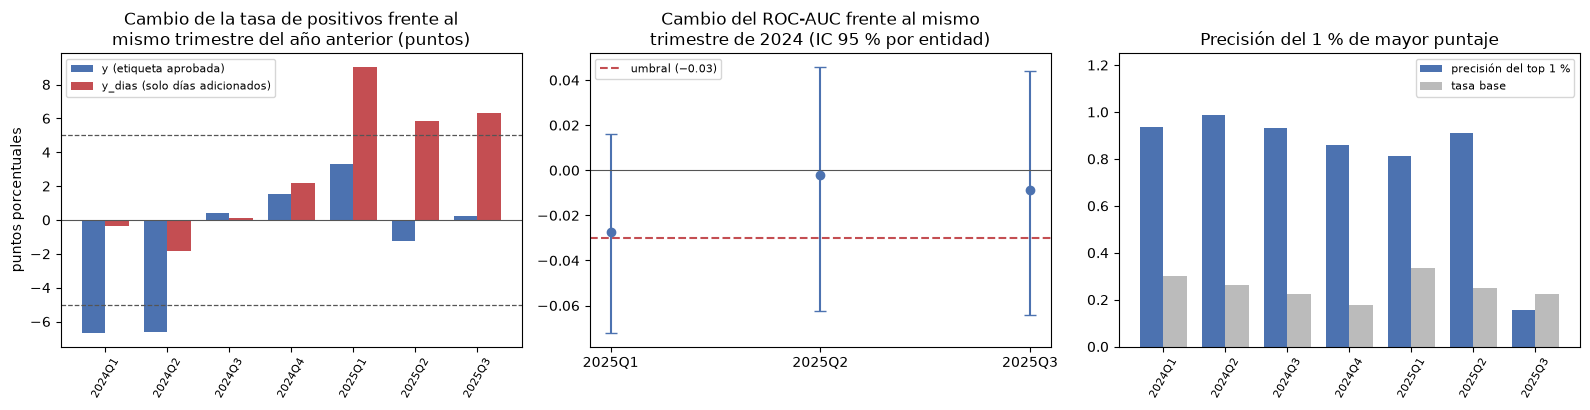

,trimestre,madurez,tasa_y,tasa_y_dias,delta_tasa_y_dias,roc_auc,precision_top,concentracion_top
0,2024Q1,0.999,0.301,0.130,-0.004,0.771,0.935,0.354
1,2024Q2,0.995,0.262,0.130,-0.018,0.737,0.989,0.870
2,2024Q3,0.993,0.223,0.109,0.001,0.752,0.931,0.313
3,2024Q4,0.991,0.178,0.112,0.022,0.847,0.860,0.532
4,2025Q1,0.998,0.334,0.220,0.091,0.743,0.812,0.373
5,2025Q2,0.992,0.249,0.188,0.058,0.735,0.911,0.464
6,2025Q3,0.984,0.225,0.172,0.063,0.743,0.154,0.819
7,2025Q4,0.914,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
t = trimestral.copy()
completos = t[t["completo"]]

fig, ejes = plt.subplots(1, 3, figsize=(16, 4.2))
dt = completos.dropna(subset=["delta_tasa_y"])
i0 = np.arange(len(dt)); ancho0 = 0.38
ejes[0].bar(i0 - ancho0 / 2, 100 * dt["delta_tasa_y"], ancho0, label="y (etiqueta aprobada)", color="#4C72B0")
ejes[0].bar(i0 + ancho0 / 2, 100 * dt["delta_tasa_y_dias"], ancho0, label="y_dias (solo días adicionados)", color="#C44E52")
for umbral in (-M.DELTA_TASA_BASE, M.DELTA_TASA_BASE):
    ejes[0].axhline(100 * umbral, color="#555", linestyle="--", linewidth=0.9)
ejes[0].axhline(0, color="#555", linewidth=0.8)
ejes[0].set_xticks(i0); ejes[0].set_xticklabels(dt["trimestre"], rotation=60, fontsize=8)
ejes[0].set_title("Cambio de la tasa de positivos frente al\nmismo trimestre del año anterior (puntos)")
ejes[0].set_ylabel("puntos porcentuales"); ejes[0].legend(fontsize=8, loc="upper left")

d = completos.dropna(subset=["delta_roc_auc"])
ejes[1].errorbar(d["trimestre"], d["delta_roc_auc"], yerr=[d["delta_roc_auc"] - d["ic_inf_roc_auc"], d["ic_sup_roc_auc"] - d["delta_roc_auc"]],
                 fmt="o", color="#4C72B0", capsize=4)
ejes[1].axhline(0, color="#555", linewidth=0.8)
ejes[1].axhline(-M.DELTA_ROC, color="#C44E52", linestyle="--", label=f"umbral (−{M.DELTA_ROC})")
ejes[1].set_title("Cambio del ROC-AUC frente al mismo\ntrimestre de 2024 (IC 95 % por entidad)"); ejes[1].legend(fontsize=8)

ancho = 0.38; i = np.arange(len(completos))
ejes[2].bar(i - ancho / 2, completos["precision_top"], ancho, label="precisión del top 1 %", color="#4C72B0")
ejes[2].bar(i + ancho / 2, completos["tasa_y"], ancho, label="tasa base", color="#BBBBBB")
ejes[2].set_xticks(i); ejes[2].set_xticklabels(completos["trimestre"], rotation=60, fontsize=8)
ejes[2].set_ylim(0, 1.25); ejes[2].set_title("Precisión del 1 % de mayor puntaje"); ejes[2].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

cols = ["trimestre", "madurez", "tasa_y", "tasa_y_dias", "delta_tasa_y_dias", "roc_auc", "precision_top", "concentracion_top"]
display(t[cols].round(3))

**Interpretación:**
- **`y_dias` sube y `y` no (izquierda).** Se compara cada trimestre con el mismo trimestre del año anterior para quitar la estacionalidad. En los tres trimestres completos de 2025 `y_dias` sube entre 6 y 9 puntos y `y` cambia menos de 4. El monitor salta, pero la causa es el registro de `dias_adicionados`, no un cambio de comportamiento: si se hubiera usado `y_dias` como etiqueta, **reentrenar habría sido un error**. Es la razón por la que se diagnostica antes de reentrenar. Aparte, `y` baja unos 6,7 puntos en 2024-T1 y T2 frente a 2023: es un aviso cuya causa no se evaluó [NO EVALUADO], y el ROC-AUC de esos trimestres no se degradó.
- **El ROC-AUC se mantiene (centro).** Frente al mismo trimestre de 2024 cambia −0,027, −0,002 y −0,009, con intervalos que incluyen 0: no hay degradación. El −0,027 de 2025-T1 queda cerca del umbral de 0,03, pero su intervalo [−0,072, +0,016] incluye 0 y no genera aviso. Los intervalos son anchos (±0,04 a ±0,05), así que un monitor trimestral solo detecta caídas de unos 0,05 o más.
- **El top 1 % de 2025-T3 falla (derecha).** Su precisión (0,15) queda por debajo de la tasa base (0,22) aunque el ROC-AUC global casi no cambió: el 82 % de esos contratos son de una sola entidad que no amplió sus plazos. Es un cambio de comportamiento que las métricas globales esconden, y por eso existe esta regla.
- **2025-T4 no se evalúa:** solo el 91 % de sus contratos ha madurado. Una cohorte incompleta solo tiene los contratos de plazo corto y daría una conclusión sesgada.

## Cuándo se reentrena

**Decisión:** se reentrena en cuatro casos, y nunca por un PSI alto por sí solo.

1. **Alarma de desempeño:** el ROC-AUC cae dos trimestres seguidos, o el top 1 % queda peor que el azar dos trimestres seguidos.
2. **Cambio confirmado de la etiqueta o de su registro:** primero se corrige la etiqueta y luego se reentrena.
3. **Revisión programada una vez al año**, cuando maduran los contratos del año anterior: se prueba un retador y se promueve solo si gana según la regla de abajo.
4. **Cambio estructural conocido** (una norma, una migración de plataforma) respaldado por un PSI sostenido.

**Alternativas consideradas:** reentrenar cada mes o cada trimestre sin condición.

**Por qué no:** reentrenar sin diagnosticar puede empeorar el modelo, como habría pasado con `y_dias`; y las etiquetas tardan meses en llegar, así que un reentrenamiento muy frecuente entrenaría con cohortes incompletas.

## Cómo se valida y se promueve una versión nueva

**Decisión:** campeón/retador sobre los **mismos contratos**, con intervalos por entidad.

**Regla de promoción:** el IC 95 % de la mejora en PR-AUC debe excluir 0 y el ROC-AUC no debe empeorar claramente más de 0,01.

**Alternativas consideradas:** promover al retador si su métrica es más alta; probar sobre un único trimestre.

**Por qué no:** una diferencia de milésimas puede ser ruido, y los contratos de una misma entidad están correlacionados, así que remuestrear contratos daría intervalos demasiado optimistas.

**Evidencia:** campeón (entrenado con 2019-2023) frente a retador (2019-2024), evaluados en los trimestres completos de 2025, que ninguno de los dos vio:

In [6]:
resumen = pd.DataFrame({
    "métrica": ["PR-AUC", "ROC-AUC"],
    "campeón": [cr["pr_auc_campeon"], cr["roc_auc_campeon"]],
    "retador": [cr["pr_auc_retador"], cr["roc_auc_retador"]],
    "diferencia": [cr["delta_pr_auc"]["delta"], cr["delta_roc_auc"]["delta"]],
    "IC 95 % inferior": [cr["delta_pr_auc"]["ic_inf"], cr["delta_roc_auc"]["ic_inf"]],
    "IC 95 % superior": [cr["delta_pr_auc"]["ic_sup"], cr["delta_roc_auc"]["ic_sup"]],
}).set_index("métrica")
display(resumen.round(3))
print(f"Contratos de evaluación: {cr['n_evaluacion']:,} ({', '.join(cr['trimestres'])})")
print("Decisión de la regla de promoción:", cr["decision"])
assert cr["decision"] == M.decision_promocion(cr["delta_pr_auc"], cr["delta_roc_auc"])

,campeón,retador,diferencia,IC 95 % inferior,IC 95 % superior
métrica,,,,,
PR-AUC,0.544,0.542,-0.002,-0.020,0.032
ROC-AUC,0.746,0.764,0.018,0.008,0.028


Contratos de evaluación: 80,652 (2025Q1, 2025Q2, 2025Q3)
Decisión de la regla de promoción: no promover: sin evidencia suficiente de mejora


**Interpretación:** reentrenar con un año más (2024) no mejora al modelo en 2025 según la regla: el PR-AUC del retador es 0,002 menor y su IC [−0,020, +0,032] incluye 0. El ROC-AUC sí sube (+0,018, IC [+0,008, +0,028]), pero la regla promueve según el PR-AUC, la métrica principal, y usa el ROC-AUC solo para que no empeore. La regla dice **no promover**. Tiene sentido: el modelo no se degradó (sección anterior), así que no había nada que corregir. La misma regla habría promovido a un retador que mejorara con claridad.

**Poner en producción una versión nueva:**
1. Reconstruir la base con el corte nuevo, pasar `calidad.py` y revisar la lista de fuga.
2. Entrenar el retador con la ventana que crece y buscar hiperparámetros con los folds temporales.
3. Comparar con el campeón con la regla de arriba, y revisar también las entidades no vistas y el top 1 %.
4. Guardar `modelo_prorroga_v<N>.joblib` y su `.json` (versiones del entorno, features, sha256, percentiles y umbrales, entidades vistas); `cargar_modelo` rechaza un artefacto incompatible.
5. Abrir un PR revisado por otro integrante: la app usa el modelo de mayor versión y la plataforma se redespliega con el `push`. Se verifica la paridad entre API y base, la aditividad de SHAP y los ejemplos de la app.
6. Conservar el campeón anterior un trimestre: volver atrás es revertir el commit.

## Limitaciones

- La simulación entrena con las **etiquetas finales** de 2019-2023 [SUPUESTO]; en producción real el modelo solo habría visto las disponibles el día de la puesta en marcha.
- Los umbrales se fijaron conociendo el comportamiento de 2024-2025: no hay un periodo aparte para validar las reglas del monitor [NO EVALUADO].
- En la demostración campeón-retador, el retador usa los mismos hiperparámetros del modelo v1: no se repite la búsqueda.
- Un monitor trimestral solo detecta caídas grandes del ROC-AUC (unos 0,05 o más).
- Solo está **diseñado**, no automatizado: correría como una tarea programada que consulte la API, calcule estas tablas y avise.
- Una degradación se detecta con el retraso con que llegan las etiquetas (de 6 a 12 meses).

El detalle de las reglas y su justificación está en `docs/REAJUSTE.md`.